[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch47_LabCh47_Tiny_UNet.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 47: Segmentation and the U-Net** (Part X: Seeing More).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=47](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=47)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch47 - A tiny U-Net
## Give every pixel its own label, and find out what the bridges across the U are for

This lab goes with **Chapter 47** of *The Why Book of Deep Learning, Part 2*.

A classifier gives one answer for a whole picture. A **segmentation** network gives one answer for every
pixel: "this pixel is part of the digit", "this one is background". In this lab you make a small
segmentation data set out of MNIST, build a U-Net small enough to count by hand, train it with three
different losses, score it with three different metrics, and then cut its skip connections to see what
they were carrying.

| TinyUNet | value |
|---|---|
| image | 32 × 32 × 1: one small digit on a striped, noisy background with two stray pen strokes |
| mask | 32 × 32 integers: 1 where the digit is, 0 everywhere else |
| encoder | two levels: 16 then 32 filters, two 3 × 3 convolutions each, 2 × 2 max-pooling after each |
| bottom | 8 × 8, 64 filters |
| decoder | two levels: a 2 × 2 transposed convolution (stride 2), a bridge from the encoder, two 3 × 3 convolutions |
| head | a 1 × 1 convolution to 2 channels, softmax over the channel axis |

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Make image and mask pairs, and say what fraction of the pixels is foreground | Steps 2 and 3 |
| Show why pixel accuracy flatters a segmenter | Step 4 |
| Work out IoU and Dice on a small mask by hand | Step 5 |
| Do a transposed convolution by hand and count the overlaps that cause checkerboards | Step 6 |
| Count a U-Net's parameters and follow its shapes down and up | Steps 7 to 9 |
| Say why the input size must be divisible by 2 to the number of pooling steps | Step 10 |
| Train with cross-entropy, with Dice, and with both, and read precision and recall | Steps 11 to 14 |
| Measure what the skip connections carry | Steps 15 to 17 |
| Augment an image and its mask together without spoiling the mask | Step 18 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **Runtime:** about two minutes on a laptop CPU, nearly all of it in Steps 12 to 15 (five
> training runs of about twenty seconds each). No GPU is needed. The only download is MNIST from `keras.datasets`.

> **Honest scale:** this is a miniature. The network has about 117,000 parameters, it sees 6,000 pictures
> of 32 × 32 pixels for five passes, and the "objects" are handwritten digits. Every score printed here is
> a number for comparing the runs in this notebook with each other, and for nothing else. The U-Net of the
> 2015 paper has about 31 million parameters and works on images of several hundred pixels a side.

---
## Step 1 - Imports and one seed

In [1]:
import os, time
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 47
keras.utils.set_random_seed(SEED)
np.set_printoptions(precision=3, suppress=True, linewidth=120)
t_start = time.time()
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.14.1


---
## Step 2 - Make the data: a digit on a busy background, and its mask

Nobody ships a segmentation data set inside Keras, so we make one. Each picture is a 32 × 32 canvas:

1. a **background** made of soft blobs, diagonal stripes and pixel noise;
2. two **stray pen strokes**: short bright lines that are not part of any digit;
3. one **MNIST digit**, shrunk from 28 × 28 to 16 × 16 so that its strokes are one or two pixels wide,
   painted at a random place with a random brightness.

The **mask** is the answer sheet: 1 on every pixel where the shrunken digit is more than half ink, 0
elsewhere. In real work a person draws that mask by hand, one image at a time. Here we get it for free
because we painted the digit ourselves.

The stray strokes are there on purpose. A bright thin line is sometimes digit and sometimes clutter, so a
network cannot label a pixel from its brightness alone. It has to look at the shape the pixel belongs to.

> **Predict:** the digit sits on a 16 × 16 patch of a 32 × 32 canvas, and only part of the patch is ink.
> Roughly what fraction of all pixels will be foreground: a third, a tenth, or a few per cent?

In [2]:
H = 32          # canvas side
DS = 16         # side of the shrunken digit
N_TRAIN, N_TEST = 6000, 1000

def make_scenes(digits, rng):
    """digits: (n, 28, 28) uint8. Returns images (n, H, H, 1) float32 in [0, 1] and masks (n, H, H) uint8."""
    n = len(digits)
    small = tf.image.resize(digits[..., None].astype("float32") / 255.0, (DS, DS), antialias=True).numpy()[..., 0]
    small = np.clip(small, 0.0, 1.0)
    images = np.zeros((n, H, H), "float32")
    masks = np.zeros((n, H, H), "uint8")
    yy, xx = np.mgrid[0:H, 0:H]
    for i in range(n):
        # 1. background: soft blobs + stripes + pixel noise
        blob = np.kron(rng.random((5, 5)), np.ones((8, 8)))[:H, :H]
        blob = (blob + np.roll(blob, 3, 0) + np.roll(blob, -3, 0) + np.roll(blob, 3, 1) + np.roll(blob, -3, 1)) / 5
        angle, period = rng.uniform(0, np.pi), rng.uniform(3, 7)
        stripes = 0.5 + 0.5 * np.sin((xx * np.cos(angle) + yy * np.sin(angle)) * 2 * np.pi / period + rng.uniform(0, 6.28))
        canvas = 0.45 * blob + 0.25 * stripes + rng.normal(0, 0.08, (H, H))
        # 2. two stray pen strokes (clutter, NOT in the mask)
        for _ in range(2):
            x0, y0 = rng.integers(0, H, 2)
            a, length = rng.uniform(0, np.pi), rng.integers(6, 14)
            t = np.arange(length)
            px = np.clip((x0 + t * np.cos(a)).astype(int), 0, H - 1)
            py = np.clip((y0 + t * np.sin(a)).astype(int), 0, H - 1)
            canvas[py, px] = np.maximum(canvas[py, px], rng.uniform(0.7, 1.0))
        # 3. the digit, at a random place and brightness
        oy, ox = rng.integers(0, H - DS + 1, 2)
        ink = rng.uniform(0.7, 1.0)
        patch = canvas[oy:oy + DS, ox:ox + DS]
        canvas[oy:oy + DS, ox:ox + DS] = patch * (1 - small[i]) + ink * small[i]
        masks[i, oy:oy + DS, ox:ox + DS] = small[i] > 0.5
        images[i] = np.clip(canvas, 0.0, 1.0)
    return images[..., None], masks

(digits_train, labels_train), (digits_test, labels_test) = keras.datasets.mnist.load_data()
rng = np.random.default_rng(0)
x_train, m_train = make_scenes(digits_train[:N_TRAIN], rng)
x_test, m_test = make_scenes(digits_test[:N_TEST], rng)

print("train images:", x_train.shape, x_train.dtype, "| train masks:", m_train.shape, m_train.dtype)
print("test  images:", x_test.shape, "| test  masks:", m_test.shape)
print("mask values :", np.unique(m_train))
FG_TRAIN, FG_TEST = m_train.mean(), m_test.mean()
print(f"foreground fraction: train {FG_TRAIN:.4f}, test {FG_TEST:.4f}")
print(f"foreground pixels per picture: mean {m_test.sum(axis=(1, 2)).mean():.1f} of {H * H}")

train images: (6000, 32, 32, 1) float32 | train masks: (6000, 32, 32) uint8
test  images: (1000, 32, 32, 1) | test  masks: (1000, 32, 32)
mask values : [0 1]
foreground fraction: train 0.0325, test 0.0300
foreground pixels per picture: mean 30.7 of 1024


### Why we see this

The images are `(6000, 32, 32, 1)`: a batch of one-channel pictures, as in Chapter 14. The masks are
`(6000, 32, 32)`: **one integer per pixel, with no channel axis**, exactly as a class label for a whole
picture is one integer with no extra axis. A segmentation label has the height and width of the image.

About 3% of the pixels are foreground: some thirty pixels in a picture of 1,024. That imbalance is typical
of real segmentation (a lesion in a scan, a road sign in a street scene), and Step 4 shows the trouble it
causes.

---
## Step 3 - Look at the pairs

> **Predict:** before you look, will you be able to tell the stray strokes from the digit in every picture?

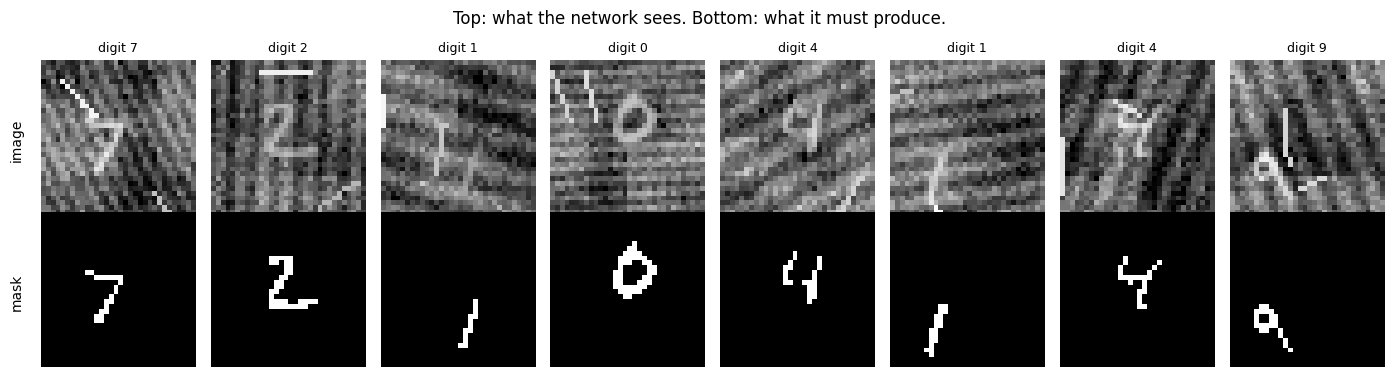

In [3]:
fig, ax = plt.subplots(2, 8, figsize=(14, 3.8))
for k in range(8):
    ax[0, k].imshow(x_test[k, ..., 0], cmap="gray", vmin=0, vmax=1)
    ax[1, k].imshow(m_test[k], cmap="gray", vmin=0, vmax=1)
    ax[0, k].set_title(f"digit {labels_test[k]}", fontsize=9)
    ax[0, k].axis("off"); ax[1, k].axis("off")
ax[0, 0].text(-4, 16, "image", rotation=90, va="center", ha="right")
ax[1, 0].text(-4, 16, "mask", rotation=90, va="center", ha="right")
plt.suptitle("Top: what the network sees. Bottom: what it must produce.")
plt.tight_layout(); plt.show()

### Why we see this

The digit is thin, sometimes fainter than the stripes it sits on, and the stray strokes look very like a
handwritten 1. Some pictures are hard for a person. That is deliberate: a task that can be solved by
"label every bright pixel" would teach nothing about architecture.

---
## Step 4 - The trap: a model that finds nothing scores about 97%

Before training anything, score the laziest possible segmenter: one that answers "background" for every
pixel of every picture. We need three metrics, all computed from three counts over the test set:

- **TP**: pixels predicted digit that are digit; **FP**: predicted digit, really background;
  **FN**: predicted background, really digit.
- **pixel accuracy** = the fraction of all pixels labelled correctly.
- **IoU** (intersection over union, also called the Jaccard index) = TP / (TP + FP + FN).
- **Dice** = 2·TP / (2·TP + FP + FN).

Neither IoU nor Dice contains the count of background pixels that were correctly called background.

> **Predict:** the pixel accuracy, the IoU and the Dice of "always background".

In [4]:
def seg_scores(pred, true):
    """pred, true: integer or boolean masks of the same shape. Counts are pooled over the whole array."""
    p, t = pred.astype(bool), true.astype(bool)
    tp = int((p & t).sum()); fp = int((p & ~t).sum()); fn = int((~p & t).sum()); tn = int((~p & ~t).sum())
    return {
        "acc": (tp + tn) / p.size,
        "iou": tp / max(1, tp + fp + fn),
        "dice": 2 * tp / max(1, 2 * tp + fp + fn),
        "precision": tp / max(1, tp + fp),
        "recall": tp / max(1, tp + fn),
        "iou_bg": tn / max(1, tn + fp + fn),
    }

def show(name, s):
    print(f"{name:26s} pixel acc {s['acc']:.4f} | IoU {s['iou']:.4f} | Dice {s['dice']:.4f} | "
          f"precision {s['precision']:.3f} | recall {s['recall']:.3f}")

always_bg = seg_scores(np.zeros_like(m_test), m_test)
show("always background", always_bg)
print(f"background IoU of that model: {always_bg['iou_bg']:.4f}  ->  mean IoU over the 2 classes: "
      f"{(always_bg['iou'] + always_bg['iou_bg']) / 2:.4f}")

always background          pixel acc 0.9700 | IoU 0.0000 | Dice 0.0000 | precision 0.000 | recall 0.000
background IoU of that model: 0.9700  ->  mean IoU over the 2 classes: 0.4850


### Why we see this

A model that has learnt nothing is right on 97% of the pixels, because 97% of the pixels are background.
Its IoU and Dice are zero, which is the honest score for a segmenter that never finds the object.

Keep 0.970 in mind for the rest of the lab. A trained network that reports "98% pixel accuracy" has
improved on doing nothing by one point. Pixel accuracy is not wrong; it is answering a question nobody
asked.

The last line shows a quieter version of the same trap. **Mean IoU** averages the IoU of every class,
background included. The background class scores 0.97 for a model that finds nothing, so the mean of the
two is about 0.49, which sounds like half-way there. Always look at the per-class numbers.

---
## Step 5 - IoU and Dice by hand on a tiny mask

Two masks on a 6 × 6 grid. The truth is a block of 8 pixels. The prediction is also 8 pixels, shifted one
column to the right, so 4 of them overlap.

> **Predict:** IoU = overlap / union and Dice = 2 × overlap / (size of one + size of the other). Work out
> both, and the pixel accuracy, before running.

In [5]:
truth = np.zeros((6, 6), int); truth[1:5, 1:3] = 1          # 4 rows x 2 columns = 8 pixels
guess = np.zeros((6, 6), int); guess[1:5, 2:4] = 1          # the same block, one column to the right
overlap = int((truth & guess).sum()); union = int((truth | guess).sum())
print("truth:\n", truth); print("guess:\n", guess)
print(f"truth {truth.sum()} px, guess {guess.sum()} px, overlap {overlap} px, union {union} px")
iou = overlap / union
dice = 2 * overlap / (truth.sum() + guess.sum())
acc = (truth == guess).mean()
print(f"IoU  = {overlap}/{union} = {iou:.3f}")
print(f"Dice = 2*{overlap}/({truth.sum()}+{guess.sum()}) = {dice:.3f}")
print(f"pixel accuracy = {(truth == guess).sum()}/36 = {acc:.3f}")
print(f"Dice from IoU: 2*IoU/(1+IoU) = {2 * iou / (1 + iou):.3f}")
s = seg_scores(guess, truth)
assert abs(s["iou"] - iou) < 1e-9 and abs(s["dice"] - dice) < 1e-9

truth:
 [[0 0 0 0 0 0]
 [0 1 1 0 0 0]
 [0 1 1 0 0 0]
 [0 1 1 0 0 0]
 [0 1 1 0 0 0]
 [0 0 0 0 0 0]]
guess:
 [[0 0 0 0 0 0]
 [0 0 1 1 0 0]
 [0 0 1 1 0 0]
 [0 0 1 1 0 0]
 [0 0 1 1 0 0]
 [0 0 0 0 0 0]]
truth 8 px, guess 8 px, overlap 4 px, union 12 px
IoU  = 4/12 = 0.333
Dice = 2*4/(8+8) = 0.500
pixel accuracy = 28/36 = 0.778
Dice from IoU: 2*IoU/(1+IoU) = 0.500


### Why we see this

Half of the predicted pixels are in the right place, and the three metrics describe that same prediction
very differently. Pixel accuracy still looks comfortable because 24 of the 36 pixels are background that
both masks agree on. IoU is the strictest.

Dice and IoU are the same information on two scales: Dice = 2·IoU / (1 + IoU), so one can always be
computed from the other and they always rank two models in the same order on the same counts. Dice is
never smaller than IoU. When a paper reports one and you are used to the other, convert before you compare.

---
## Step 6 - Transposed convolution by hand, and the overlap that makes checkerboards

The second half of a U-Net must make feature maps **bigger**. Chapter 15 introduced the layer that does it
with learnt weights: a transposed convolution. Each input cell **stamps** a copy of the kernel onto the
output, scaled by the cell's value; with stride 2 the next stamp lands two cells along; where stamps
overlap they add.

We do it with NumPy on a 2 × 2 input `[[1, 2], [3, 4]]` and a 3 × 3 kernel of ones, then ask Keras for the
same thing.

> **Predict:** the output side is (in − 1) × stride + kernel. How big is the output? Which single output
> cell receives all four stamps, and what number will it hold?

In [6]:
def transposed_conv_by_hand(x, k, stride):
    n, ks = x.shape[0], k.shape[0]
    out = np.zeros(((n - 1) * stride + ks, (n - 1) * stride + ks))
    for r in range(n):
        for c in range(n):
            out[r * stride:r * stride + ks, c * stride:c * stride + ks] += x[r, c] * k     # one stamp
    return out

x_small = np.array([[1.0, 2.0], [3.0, 4.0]])
by_hand = transposed_conv_by_hand(x_small, np.ones((3, 3)), stride=2)
print("input:\n", x_small); print("by hand, 3x3 kernel of ones, stride 2:\n", by_hand)

layer = layers.Conv2DTranspose(1, 3, strides=2, padding="valid", use_bias=False)
layer.build((None, 2, 2, 1))
layer.set_weights([np.ones((3, 3, 1, 1), "float32")])
by_keras = layer(x_small.reshape(1, 2, 2, 1)).numpy()[0, ..., 0]
print("largest difference from Keras:", np.abs(by_keras - by_hand).max())
assert np.allclose(by_keras, by_hand)

flat = np.ones((4, 4))
print("\na FLAT input of ones, 3x3 kernel, stride 2 (stamps landing on each cell):\n",
      transposed_conv_by_hand(flat, np.ones((3, 3)), 2).astype(int))
print("the same flat input, 2x2 kernel, stride 2:\n", transposed_conv_by_hand(flat, np.ones((2, 2)), 2).astype(int))

input:
 [[1. 2.]
 [3. 4.]]
by hand, 3x3 kernel of ones, stride 2:
 [[ 1.  1.  3.  2.  2.]
 [ 1.  1.  3.  2.  2.]
 [ 4.  4. 10.  6.  6.]
 [ 3.  3.  7.  4.  4.]
 [ 3.  3.  7.  4.  4.]]
largest difference from Keras: 0.0

a FLAT input of ones, 3x3 kernel, stride 2 (stamps landing on each cell):
 [[1 1 2 1 2 1 2 1 1]
 [1 1 2 1 2 1 2 1 1]
 [2 2 4 2 4 2 4 2 2]
 [1 1 2 1 2 1 2 1 1]
 [2 2 4 2 4 2 4 2 2]
 [1 1 2 1 2 1 2 1 1]
 [2 2 4 2 4 2 4 2 2]
 [1 1 2 1 2 1 2 1 1]
 [1 1 2 1 2 1 2 1 1]]
the same flat input, 2x2 kernel, stride 2:
 [[1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1]]


### Why we see this

A 2 × 2 input became 5 × 5: (2 − 1) × 2 + 3. The centre cell holds 1 + 2 + 3 + 4 = 10 because all four
stamps cover it; the corners hold a single stamp each. NumPy and Keras agree exactly.

The third print is the important one. The input is perfectly flat, every weight is 1, and the output is
**not** flat: cells receive 1, 2 or 4 stamps in a regular grid. That pattern is there before any learning
has happened. In an image it shows as a faint checkerboard, and the network has to spend weights learning
to cancel it.

The fourth print is one cure: a kernel the same size as the stride (2 × 2 with stride 2) tiles the output
with no overlap at all, so every cell gets exactly one stamp. That is the layer this lab's U-Net uses, and
the one in the 2015 U-Net paper. The other cure is to resize first (`UpSampling2D`) and then apply an
ordinary convolution.

---
## Step 7 - Count the U-Net before building it

One formula from Chapter 14 covers every layer: (kernel height × kernel width × channels in + 1) ×
channels out. A transposed convolution uses the same formula. Pooling and concatenation have no weights.

The only new thing to watch is the **channel count after a bridge**. `Concatenate` stacks the encoder's
map on top of the decoder's map, so the convolution that follows sees the **sum** of the two channel
counts.

> **Predict:** at the lower bridge the decoder brings 32 channels up and the encoder sends 32 across. How
> many channels does the next convolution see, and how many parameters does it have with 32 filters?

In [7]:
def conv_params(k, c_in, c_out):
    return (k * k * c_in + 1) * c_out

hand = [
    ("down1_conv1  3x3,  1 -> 16", conv_params(3, 1, 16)),
    ("down1_conv2  3x3, 16 -> 16", conv_params(3, 16, 16)),
    ("down2_conv1  3x3, 16 -> 32", conv_params(3, 16, 32)),
    ("down2_conv2  3x3, 32 -> 32", conv_params(3, 32, 32)),
    ("bottom_conv1 3x3, 32 -> 64", conv_params(3, 32, 64)),
    ("bottom_conv2 3x3, 64 -> 64", conv_params(3, 64, 64)),
    ("up2          2x2, 64 -> 32 (transposed)", conv_params(2, 64, 32)),
    ("dec2_conv1   3x3, 32+32 -> 32  <- bridge", conv_params(3, 32 + 32, 32)),
    ("dec2_conv2   3x3, 32 -> 32", conv_params(3, 32, 32)),
    ("up1          2x2, 32 -> 16 (transposed)", conv_params(2, 32, 16)),
    ("dec1_conv1   3x3, 16+16 -> 16  <- bridge", conv_params(3, 16 + 16, 16)),
    ("dec1_conv2   3x3, 16 -> 16", conv_params(3, 16, 16)),
    ("head         1x1, 16 -> 2", conv_params(1, 16, 2)),
]
for name, n in hand:
    print(f"{name:44s} {n:>7,}")
UNET_HAND = sum(n for _, n in hand)
print(f"{'total':44s} {UNET_HAND:>7,}")
NOSKIP_HAND = UNET_HAND - conv_params(3, 64, 32) + conv_params(3, 32, 32) - conv_params(3, 32, 16) + conv_params(3, 16, 16)
print(f"{'the same network without the two bridges':44s} {NOSKIP_HAND:>7,}")
print(f"encoder {sum(n for _, n in hand[:4]):,} | bottom {sum(n for _, n in hand[4:6]):,} | "
      f"decoder + head {sum(n for _, n in hand[6:]):,}")

down1_conv1  3x3,  1 -> 16                       160
down1_conv2  3x3, 16 -> 16                     2,320
down2_conv1  3x3, 16 -> 32                     4,640
down2_conv2  3x3, 32 -> 32                     9,248
bottom_conv1 3x3, 32 -> 64                    18,496
bottom_conv2 3x3, 64 -> 64                    36,928
up2          2x2, 64 -> 32 (transposed)        8,224
dec2_conv1   3x3, 32+32 -> 32  <- bridge      18,464
dec2_conv2   3x3, 32 -> 32                     9,248
up1          2x2, 32 -> 16 (transposed)        2,064
dec1_conv1   3x3, 16+16 -> 16  <- bridge       4,624
dec1_conv2   3x3, 16 -> 16                     2,320
head         1x1, 16 -> 2                         34
total                                        116,770
the same network without the two bridges     105,250
encoder 16,368 | bottom 55,424 | decoder + head 44,978


### Why we see this

The network has 116,770 parameters. Nearly half of them (55,424) sit in the two convolutions at the bottom
of the U, where the maps are smallest and the channels are most numerous: the same pattern as every CNN in
Part 1.

The bridges are not free. `dec2_conv1` reads 64 channels instead of 32, which costs 18,464 parameters
instead of 9,248. Take both bridges away and the count falls by 11,520 to 105,250. Remember this number in
Step 15: the network without bridges is about 10% smaller, so a fair reader will ask whether size explains
the difference. Step 15 tests that too.

---
## Step 8 - Build it

`build_unet` is written to be reused. `skips=False` removes the bridges (Step 15). `up="resize"` swaps
the transposed convolution for resize-then-convolve (Trial 4). `out_channels` and `out_activation` set the
head: 2 channels with softmax for this lab, and Chapter 50 will call the same function with one channel
and no activation to predict noise.

> **Predict:** the output shape for an input batch of `(None, 32, 32, 1)`. How many output channels does a
> "digit or not" segmenter need: one or two?

In [8]:
def conv_block(x, filters, name):
    """Two 3x3 convolutions that keep height and width."""
    x = layers.Conv2D(filters, 3, padding="same", activation="relu", name=name + "_conv1")(x)
    x = layers.Conv2D(filters, 3, padding="same", activation="relu", name=name + "_conv2")(x)
    return x

def build_unet(input_shape=(32, 32, 1), base=16, depth=2, out_channels=2, out_activation="softmax",
               skips=True, up="transpose", name="unet"):
    """A small U-Net. depth = number of pooling steps; channels are base, 2*base, ... on the way down.
    Height and width must be divisible by 2**depth."""
    inputs = layers.Input(shape=input_shape, name="image")
    x, bridges = inputs, []
    for i in range(depth):                                   # the contracting path
        x = conv_block(x, base * 2 ** i, f"down{i + 1}")
        bridges.append(x)                                    # remember the sharp map
        x = layers.MaxPooling2D(2, name=f"pool{i + 1}")(x)
    x = conv_block(x, base * 2 ** depth, "bottom")           # the bottom of the U
    for i in reversed(range(depth)):                         # the expanding path
        f = base * 2 ** i
        if up == "transpose":
            x = layers.Conv2DTranspose(f, 2, strides=2, padding="same", name=f"up{i + 1}")(x)
        else:
            x = layers.UpSampling2D(2, interpolation="nearest", name=f"grow{i + 1}")(x)
            x = layers.Conv2D(f, 3, padding="same", activation="relu", name=f"up{i + 1}")(x)
        if skips:
            x = layers.Concatenate(name=f"bridge{i + 1}")([bridges[i], x])
        x = conv_block(x, f, f"dec{i + 1}")
    outputs = layers.Conv2D(out_channels, 1, activation=out_activation, name="head")(x)
    return keras.Model(inputs, outputs, name=name)

unet = build_unet()
unet.summary(line_length=92)
print("hand count :", f"{UNET_HAND:,}")
print("Keras count:", f"{unet.count_params():,}")
assert unet.count_params() == UNET_HAND == 116_770
assert build_unet(skips=False).count_params() == NOSKIP_HAND == 105_250

Model: "unet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)             ┃ Output Shape          ┃       Param # ┃ Connected to          ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)       │ (None, 32, 32, 1)     │             0 │ -                     │
├──────────────────────────┼───────────────────────┼───────────────┼───────────────────────┤
│ down1_conv1 (Conv2D)     │ (None, 32, 32, 16)    │           160 │ image[0][0]           │
├──────────────────────────┼───────────────────────┼───────────────┼───────────────────────┤
│ down1_conv2 (Conv2D)     │ (None, 32, 32, 16)    │         2,320 │ down1_conv1[0][0]     │
├──────────────────────────┼───────────────────────┼───────────────┼───────────────────────┤
│ pool1 (MaxPooling2D)     │ (None, 16, 16, 16)    │             0 │ down1_conv2[0][0]     │
├──────────────────────────┼───────────────────────┼───────────────┼───────────────────────┤
│ down2_conv1 (Conv2D)     │ (None, 16, 16, 32)    │         4,640 │ pool1[0][0]           │
├──────────────────────────┼───────────────────────┼───────────────┼───────────────────────┤
│ down2_conv2 (Conv2D)     │ (None, 16, 16, 32)    │         9,248 │ down2_conv1[0][0]     │
├──────────────────────────┼───────────────────────┼───────────────┼───────────────────────┤
│ pool2 (MaxPooling2D)     │ (None, 8, 8, 32)      │             0 │ down2_conv2[0][0]     │
├──────────────────────────┼───────────────────────┼───────────────┼───────────────────────┤
│ bottom_conv1 (Conv2D)    │ (None, 8, 8, 64)      │        18,496 │ pool2[0][0]           │
├──────────────────────────┼───────────────────────┼───────────────┼───────────────────────┤
│ bottom_conv2 (Conv2D)    │ (None, 8, 8, 64)      │        36,928 │ bottom_conv1[0][0]    │
├──────────────────────────┼───────────────────────┼───────────────┼───────────────────────┤
│ up2 (Conv2DTranspose)    │ (None, 16, 16, 32)    │         8,224 │ bottom_conv2[0][0]    │
├──────────────────────────┼───────────────────────┼───────────────┼───────────────────────┤
│ bridge2 (Concatenate)    │ (None, 16, 16, 64)    │             0 │ down2_conv2[0][0],    │
│                          │                       │               │ up2[0][0]             │
├──────────────────────────┼───────────────────────┼───────────────┼───────────────────────┤
│ dec2_conv1 (Conv2D)      │ (None, 16, 16, 32)    │        18,464 │ bridge2[0][0]         │
├──────────────────────────┼───────────────────────┼───────────────┼───────────────────────┤
│ dec2_conv2 (Conv2D)      │ (None, 16, 16, 32)    │         9,248 │ dec2_conv1[0][0]      │
├──────────────────────────┼───────────────────────┼───────────────┼───────────────────────┤
│ up1 (Conv2DTranspose)    │ (None, 32, 32, 16)    │         2,064 │ dec2_conv2[0][0]      │
├──────────────────────────┼───────────────────────┼───────────────┼───────────────────────┤
│ bridge1 (Concatenate)    │ (None, 32, 32, 32)    │             0 │ down1_conv2[0][0],    │
│                          │                       │               │ up1[0][0]             │
├──────────────────────────┼───────────────────────┼───────────────┼───────────────────────┤
│ dec1_conv1 (Conv2D)      │ (None, 32, 32, 16)    │         4,624 │ bridge1[0][0]         │
├──────────────────────────┼───────────────────────┼───────────────┼───────────────────────┤
│ dec1_conv2 (Conv2D)      │ (None, 32, 32, 16)    │         2,320 │ dec1_conv1[0][0]      │
├──────────────────────────┼───────────────────────┼───────────────┼───────────────────────┤
│ head (Conv2D)            │ (None, 32, 32, 2)     │            34 │ dec1_conv2[0][0]      │
└──────────────────────────┴───────────────────────┴───────────────┴───────────────────────┘

 Total params: 116,770 (456.13 KB)

 Trainable params: 116,770 (456.13 KB)

 Non-trainable params: 0 (0.00 B)

hand count : 116,770
Keras count: 116,770


### Why we see this

The counts match. The output is `(None, 32, 32, 2)`: for every pixel, two numbers that sum to 1, the
probability of class 0 (background) and of class 1 (digit).

Two channels, not one, because **background is a class**. With one kind of object there are two classes,
and with five kinds of object there are six. Forgetting to count class 0 is one of the commonest
off-by-one mistakes in segmentation code. (For exactly two classes a single sigmoid channel also works.
The two-channel softmax is used here because it is the form that extends to any number of classes.)

---
## Step 9 - Follow the shapes down and up

> **Predict:** write the shape after every named step: `down1`, `pool1`, `down2`, `pool2`, `bottom`,
> `up2`, `bridge2`, `dec2`, `up1`, `bridge1`, `dec1`, `head`.

In [9]:
EXPECT = {
    "down1_conv2": (32, 32, 16), "pool1": (16, 16, 16),
    "down2_conv2": (16, 16, 32), "pool2": (8, 8, 32),
    "bottom_conv2": (8, 8, 64),
    "up2": (16, 16, 32), "bridge2": (16, 16, 64), "dec2_conv2": (16, 16, 32),
    "up1": (32, 32, 16), "bridge1": (32, 32, 32), "dec1_conv2": (32, 32, 16),
    "head": (32, 32, 2),
}
for lname, shape in EXPECT.items():
    got = tuple(unet.get_layer(lname).output.shape[1:])
    note = "  <- 32 from below + 32 from across" if lname == "bridge2" else "  <- 16 + 16" if lname == "bridge1" else ""
    print(f"{lname:14s} {str(got):14s}{note}")
    assert got == shape, (lname, got, shape)

probs = unet.predict(x_test[:4], verbose=0)
print("\noutput batch:", probs.shape)
print("the two numbers at pixel (0, 0) of picture 0:", probs[0, 0, 0], "sum", probs[0, 0, 0].sum())
print("sum over the LAST axis is 1 at every pixel:", np.allclose(probs.sum(axis=-1), 1.0, atol=1e-5))
print("sum over axis 1 (the wrong axis), first values:", probs.sum(axis=1)[0, :3, 0])

down1_conv2    (32, 32, 16)  
pool1          (16, 16, 16)  
down2_conv2    (16, 16, 32)  
pool2          (8, 8, 32)    
bottom_conv2   (8, 8, 64)    
up2            (16, 16, 32)  
bridge2        (16, 16, 64)    <- 32 from below + 32 from across
dec2_conv2     (16, 16, 32)  
up1            (32, 32, 16)  
bridge1        (32, 32, 32)    <- 16 + 16
dec1_conv2     (32, 32, 16)  
head           (32, 32, 2)   



output batch: (4, 32, 32, 2)
the two numbers at pixel (0, 0) of picture 0: [0.498 0.502] sum 1.0
sum over the LAST axis is 1 at every pixel: True
sum over axis 1 (the wrong axis), first values: [16.083 16.038 16.009]


### Why we see this

Down the left side the maps halve and the channels double: 32 → 16 → 8 pixels, 16 → 32 → 64 channels. Up
the right side they do the reverse. At each bridge the channel count is the sum of what came up and what
came across (64 at the lower bridge, 32 at the upper), and the two convolutions that follow bring it back
down.

The softmax runs over the **last** axis: the two class scores of one pixel compete with each other, and
nothing else does. A softmax over axis 1 or 2 would make the pixels of a column compete with each other,
which runs without any error message and trains a network that cannot work. `layers.Softmax` and the
`activation="softmax"` argument both use the last axis by default, which is the right one for
channels-last data.

---
## Step 10 - Why 32 and not 30

This U-Net pools twice, so it divides the side by 4. Try an input whose side is not divisible by 4.

> **Predict:** 30 → pool → ? → pool → ? → up → ? → up → ?. At which bridge do the two maps disagree?

In [10]:
for side in (32, 30, 28):
    down = [side]
    for _ in range(2):
        down.append(down[-1] // 2)                    # pooling rounds down
    up2 = down[2] * 2                                 # after the first upsampling
    print(f"side {side}: down {down[0]} -> {down[1]} -> {down[2]},  up -> {up2}  (encoder kept {down[1]})",
          "ok" if up2 == down[1] else "MISMATCH")
try:
    build_unet(input_shape=(30, 30, 1))
    print("built without complaint")
except ValueError as e:
    print("\nValueError:", str(e).strip().splitlines()[0][:230])

side 32: down 32 -> 16 -> 8,  up -> 16  (encoder kept 16) ok
side 30: down 30 -> 15 -> 7,  up -> 14  (encoder kept 15) MISMATCH
side 28: down 28 -> 14 -> 7,  up -> 14  (encoder kept 14) ok

ValueError: A `Concatenate` layer requires inputs with matching shapes except for the concatenation axis. Received: input_shape=[(None, 15, 15, 32), (None, 14, 14, 32)]


### Why we see this

30 pools to 15, and 15 pools to 7 because pooling rounds down. Coming back up, 7 doubles to 14, and the
bridge tries to stack a 14 × 14 map on a 15 × 15 one. Keras refuses when the model is built, which is the
kind refusal: the error names the `Concatenate` layer and the two shapes.

The rule: **height and width must be divisible by 2 to the power of the number of pooling steps.** Here
that is 4, so 28 and 32 work and 30 does not. A U-Net with four pooling steps needs multiples of 16. Real
images rarely oblige, so they are padded or cropped to the next multiple before the network and the
output is cropped back.

---
## Step 11 - Three losses

**Cross-entropy** treats every pixel as a small classification problem and averages over all of them. With
97% background, 97% of that average is about pixels that are easy.

**Dice loss** is 1 minus a soft version of the Dice score from Step 5, computed with probabilities instead
of hard 0/1 decisions so that it has a gradient. Background pixels that are correctly called background
do not appear in it at all.

> **Predict:** a network that outputs probability 0.5 of "digit" on every pixel, on masks that are 3%
> foreground. Is its Dice loss near 0, near 0.5 or near 1?

In [11]:
sce = keras.losses.SparseCategoricalCrossentropy()

def dice_loss(y_true, y_pred, smooth=1.0):
    """Soft Dice, pooled over the whole batch. y_true: (B, H, W) integers; y_pred: (B, H, W, 2) probabilities."""
    t = tf.cast(y_true, tf.float32)
    p = y_pred[..., 1]                                   # probability of class 1 (digit)
    overlap = tf.reduce_sum(t * p)
    total = tf.reduce_sum(t) + tf.reduce_sum(p)
    return 1.0 - (2.0 * overlap + smooth) / (total + smooth)

def ce_plus_dice(y_true, y_pred):
    return sce(y_true, y_pred) + dice_loss(y_true, y_pred)

half = np.full((64, H, H, 2), 0.5, "float32")
perfect = np.stack([1.0 - m_test[:64], m_test[:64]], axis=-1).astype("float32")
nothing = np.stack([np.full((64, H, H), 0.99), np.full((64, H, H), 0.01)], axis=-1).astype("float32")
for name, pred in [("0.5 everywhere", half), ("background, 99% sure", nothing), ("perfect", perfect)]:
    ce = float(sce(m_test[:64], np.clip(pred, 1e-7, 1.0)))
    print(f"{name:22s} cross-entropy {ce:7.4f} | Dice loss {float(dice_loss(m_test[:64], pred)):.4f}")

0.5 everywhere         cross-entropy  0.6931 | Dice loss 0.9477
background, 99% sure   cross-entropy  0.1367 | Dice loss 0.9849


perfect                cross-entropy  0.0000 | Dice loss 0.0000

### Why we see this

Compare the first two rows. Going from "0.5 everywhere" to "background, 99% sure" cuts the cross-entropy
from 0.69 to 0.14: by that loss, giving up on the digit is a large improvement, because it is right on
97% of the pixels. The Dice loss moves the other way, from 0.95 to 0.98: finding nothing is as bad as a
loss can be. The two losses disagree about how bad it is to find nothing, and that is the whole reason
Dice loss exists.

The first row also shows a weakness. At the start of training, when every pixel is near 0.5, the Dice
loss is already 0.95 and has very little room left to say "worse". Keep that in mind for Step 13.

---
## Step 12 - Train with cross-entropy

One helper trains a fresh network and scores it, so that every run in this lab is treated the same way:
the same seed, the same 6,000 pictures, 5 passes, batches of 32, Adam at 0.002.

> **Predict:** "always background" scores 0.970 pixel accuracy and 0 IoU. After training, which of the two
> numbers will have moved more?

In [12]:
EPOCHS, BATCH, LR = 5, 32, 2e-3
results, models, histories = {}, {}, {}

def predict_masks(model, x):
    return model.predict(x, batch_size=250, verbose=0).argmax(axis=-1)      # the likelier class per pixel

def train_and_score(label, loss, epochs=EPOCHS, **build_kwargs):
    keras.utils.set_random_seed(SEED)
    model = build_unet(**build_kwargs)
    model.compile(optimizer=keras.optimizers.Adam(LR), loss=loss)
    t0 = time.time()
    hist = model.fit(x_train, m_train, batch_size=BATCH, epochs=epochs, verbose=0)
    s = seg_scores(predict_masks(model, x_test), m_test)
    s["seconds"] = time.time() - t0
    results[label], models[label], histories[label] = s, model, hist.history["loss"]
    print("loss per epoch:", " ".join(f"{v:.3f}" for v in hist.history["loss"]), f"  ({s['seconds']:.0f} s)")
    show(label, s)
    return model

show("always background", always_bg)
unet_ce = train_and_score("U-Net, cross-entropy", sce)

always background          pixel acc 0.9700 | IoU 0.0000 | Dice 0.0000 | precision 0.000 | recall 0.000


loss per epoch: 0.125 0.042 0.033 0.029 0.027   (46 s)
U-Net, cross-entropy       pixel acc 0.9897 | IoU 0.6924 | Dice 0.8183 | precision 0.864 | recall 0.777


### Why we see this

Pixel accuracy rose from 0.970 to 0.990: two points, and on that scale the trained network and the one
that finds nothing look like neighbours. IoU rose from 0 to 0.69. Same network, same predictions: only
the question changed.

An IoU of 0.69 is not a failure of the code. IoU is harsh on thin objects: when a stroke is one or two
pixels wide, almost every foreground pixel is an edge pixel (Step 16 counts them), and a prediction that
is one pixel too fat or too thin loses a large share of the overlap. The same skill on fat blobs would
score far higher.

Precision is 0.86 and recall 0.78: this network would sooner miss a digit pixel than raise a false alarm.
That is what a loss dominated by background pixels teaches.

---
## Step 13 - Train with Dice loss

Same network, same data, same schedule. Only the loss changes, to the batch-pooled `dice_loss`.

> **Predict:** Dice loss ignores the easy background. Will the network find **more** digit pixels than the
> cross-entropy one (higher recall), and what will that do to precision?

In [13]:
unet_dice = train_and_score("U-Net, Dice", dice_loss)

loss per epoch: 0.437 0.209 0.181 0.169 0.160   (62 s)
U-Net, Dice                pixel acc 0.9886 | IoU 0.7018 | Dice 0.8248 | precision 0.764 | recall 0.896


### Why we see this

IoU 0.70 against 0.69 for cross-entropy. On this task, at this size, the choice between these two losses
did not change the headline score, and it would be dishonest to pretend it did.

What changed is the **kind** of mistake. Cross-entropy gave precision 0.86 and recall 0.78. Dice gave
precision 0.76 and recall 0.90: it marks more pixels as digit, catches more of the true ones, and pays
with more false alarms. Dice rewards overlap and is indifferent to how confident the background is, so it
is more willing to say "digit" when unsure.

**A warning that this run does not show.** While this lab was being written, the same cell was run with
two other seeds. With one of them the Dice-only network ended at IoU 0.000: it had fallen into "predict
background everywhere", where the softmax is saturated, the Dice loss is flat and no gradient is left to
climb out. Cross-entropy never did that. Dice as the **only** loss is fragile when the foreground is
tiny. Change `SEED` to 1 in Step 1 if you want to watch it happen.

---
## Step 14 - Cross-entropy plus Dice

Add the two. Cross-entropy supplies a steady gradient on every pixel from the first step; Dice keeps the
pressure on the overlap.

> **Predict:** will the sum beat both of its parts on IoU by a wide margin, a narrow one, or not at all?

In [14]:
unet_both = train_and_score("U-Net, CE + Dice", ce_plus_dice)

print()
show("always background", always_bg)
for label in ["U-Net, cross-entropy", "U-Net, Dice", "U-Net, CE + Dice"]:
    show(label, results[label])

loss per epoch: 0.758 0.299 0.244 0.211 0.193   (84 s)
U-Net, CE + Dice           pixel acc 0.9903 | IoU 0.7256 | Dice 0.8410 | precision 0.824 | recall 0.858

always background          pixel acc 0.9700 | IoU 0.0000 | Dice 0.0000 | precision 0.000 | recall 0.000
U-Net, cross-entropy       pixel acc 0.9897 | IoU 0.6924 | Dice 0.8183 | precision 0.864 | recall 0.777
U-Net, Dice                pixel acc 0.9886 | IoU 0.7018 | Dice 0.8248 | precision 0.764 | recall 0.896
U-Net, CE + Dice           pixel acc 0.9903 | IoU 0.7256 | Dice 0.8410 | precision 0.824 | recall 0.858


### Why we see this

IoU 0.69, 0.70 and 0.73. The sum is ahead in this run, and its precision and recall are the most evenly
balanced of the three.

Do not make too much of the three points. With the two other seeds tried while writing this lab,
cross-entropy scored 0.73 and 0.72 and the sum scored 0.72 and 0.72: the order changed. The honest
summary is: **on this task the loss moved the balance between precision and recall, and the overlap
stayed within the noise of the seed.**

The case for combining the two is not the last decimal of IoU. It is that the sum trains as reliably as
cross-entropy (it never collapsed, on any seed) and still pushes on the quantity you report. The
advantage of an overlap loss grows as the foreground shrinks: at 3% a cross-entropy network copes; at
0.1% it often does not.

---
## Step 15 - Cut the bridges

Now the experiment the chapter is about. Build the same network with `skips=False`: the encoder, the
bottom and the decoder are all still there, but nothing crosses from left to right. Everything the decoder
knows has to come up from the 8 × 8 bottom. That is the convolutional autoencoder of Chapter 27, trained
on masks.

The second run in the cell answers a fair objection. The network without bridges has 11,520 fewer
weights, so it is also trained once more with 17 / 34 / 68 filters instead of 16 / 32 / 64, which gives it
118,781 weights: slightly **more** than the U-Net.

> **Predict:** which will suffer more without bridges: finding roughly where the digit is, or getting its
> thin strokes on exactly the right pixels? How much will pixel accuracy fall? Will the extra width help?

In [15]:
noskip = train_and_score("no bridges, CE + Dice", ce_plus_dice, skips=False, name="unet_noskip")
assert noskip.count_params() == NOSKIP_HAND

# the fair question: is it the bridges, or the 11,520 extra weights? Widen the no-bridge network to 17 / 34 / 68.
def noskip_params(b):
    return (conv_params(3, 1, b) + conv_params(3, b, b) + conv_params(3, b, 2 * b) + conv_params(3, 2 * b, 2 * b)
            + conv_params(3, 2 * b, 4 * b) + conv_params(3, 4 * b, 4 * b)
            + conv_params(2, 4 * b, 2 * b) + 2 * conv_params(3, 2 * b, 2 * b)
            + conv_params(2, 2 * b, b) + 2 * conv_params(3, b, b) + conv_params(1, b, 2))
assert noskip_params(16) == NOSKIP_HAND
print()
noskip_wide = train_and_score("no bridges, wider (17)", ce_plus_dice, skips=False, base=17, name="unet_noskip_wide")
assert noskip_wide.count_params() == noskip_params(17) == 118_781
print()
print(f"parameters: U-Net {unet_both.count_params():,} | no bridges {noskip.count_params():,} | "
      f"no bridges, wider {noskip_wide.count_params():,}")

loss per epoch: 0.891 0.467 0.376 0.332 0.302   (46 s)
no bridges, CE + Dice      pixel acc 0.9848 | IoU 0.5905 | Dice 0.7425 | precision 0.754 | recall 0.731



loss per epoch: 0.854 0.452 0.348 0.299 0.275   (47 s)
no bridges, wider (17)     pixel acc 0.9862 | IoU 0.6323 | Dice 0.7748 | precision 0.757 | recall 0.794

parameters: U-Net 116,770 | no bridges 105,250 | no bridges, wider 118,781


### Why we see this

Cutting the bridges costs 0.135 of IoU (0.726 to 0.590). Giving the bridgeless network more weights than
the U-Net wins back about a third of that (0.632). So it is the wiring, not the size. With the two other
seeds the pattern was the same: 0.72 and 0.72 with bridges, 0.62 and 0.59 without, 0.61 and 0.61 without
and wider.

Look at pixel accuracy as well: 0.990 against 0.985. Half a point. Anyone comparing these two networks by
pixel accuracy would call them equal.

---
## Step 16 - Where do the mistakes fall?

Split the test pixels into two groups using the true mask:

- **edge pixels**: any pixel with a neighbour (up, down, left or right) of the other class. These are the
  outline of the digit, on both sides of the line;
- **all the rest**: pixels deep inside the background (the digits are too thin to have much "inside").

> **Predict:** for each network, what fraction of each group is labelled wrongly?

In [16]:
def edge_pixels(masks):
    t = masks.astype(bool)
    p = np.pad(t, ((0, 0), (1, 1), (1, 1)), mode="edge")
    differs = (p[:, :-2, 1:-1] != t) | (p[:, 2:, 1:-1] != t) | (p[:, 1:-1, :-2] != t) | (p[:, 1:-1, 2:] != t)
    return differs

edges = edge_pixels(m_test)
print(f"edge pixels: {edges.mean():.1%} of all test pixels; {(edges & (m_test == 1)).sum() / (m_test == 1).sum():.1%} "
      f"of the digit pixels are edge pixels")
pred_skip, pred_noskip = predict_masks(unet_both, x_test), predict_masks(noskip, x_test)
pred_wide = predict_masks(noskip_wide, x_test)
for label, pred in [("with bridges", pred_skip), ("no bridges", pred_noskip), ("no br., wider", pred_wide)]:
    wrong = pred != m_test
    print(f"{label:13s} wrong on edge pixels {wrong[edges].mean():.1%} | wrong elsewhere {wrong[~edges].mean():.2%} | "
          f"share of all its mistakes that are on edge pixels {wrong[edges].sum() / wrong.sum():.0%}")
print()
for label in ["U-Net, CE + Dice", "no bridges, CE + Dice", "no bridges, wider (17)"]:
    show(label, results[label])
print(f"IoU lost by cutting the bridges: {results['U-Net, CE + Dice']['iou'] - results['no bridges, CE + Dice']['iou']:.3f}")
print(f"pixel accuracy lost            : {results['U-Net, CE + Dice']['acc'] - results['no bridges, CE + Dice']['acc']:.4f}")

edge pixels: 6.5% of all test pixels; 92.1% of the digit pixels are edge pixels


with bridges  wrong on edge pixels 13.2% | wrong elsewhere 0.12% | share of all its mistakes that are on edge pixels 88%
no bridges    wrong on edge pixels 22.3% | wrong elsewhere 0.07% | share of all its mistakes that are on edge pixels 96%
no br., wider wrong on edge pixels 19.7% | wrong elsewhere 0.11% | share of all its mistakes that are on edge pixels 93%

U-Net, CE + Dice           pixel acc 0.9903 | IoU 0.7256 | Dice 0.8410 | precision 0.824 | recall 0.858
no bridges, CE + Dice      pixel acc 0.9848 | IoU 0.5905 | Dice 0.7425 | precision 0.754 | recall 0.731
no bridges, wider (17)     pixel acc 0.9862 | IoU 0.6323 | Dice 0.7748 | precision 0.757 | recall 0.794
IoU lost by cutting the bridges: 0.135
pixel accuracy lost            : 0.0055


### Why we see this

Edge pixels are 6.5% of the picture and hold nearly all the mistakes of every network: 88% of the
U-Net's and 96% of the bridgeless network's. Away from the edges all three networks are right more than
99.8% of the time, and the network without bridges is, if anything, slightly better there (0.07% wrong
against 0.12%).

So the bridgeless network knows **what** and roughly **where**: it finds the digit and it is not fooled
more often by the stray strokes. What it cannot do is put the outline on the right pixels: it is wrong on
22.3% of edge pixels against 13.2%. Everything it knows about position has been through an 8 × 8 map, in
which one cell covers a 4 × 4 patch of the picture, and a stroke one pixel wide does not survive that
trip intact. The bridges hand the decoder the 32 × 32 and 16 × 16 maps from before the pooling, and the
outline comes back.

92% of the digit pixels are themselves edge pixels. That is why this task is hard on IoU and why it shows
the effect of the bridges so clearly. On fat objects with large interiors the same experiment gives a
smaller gap (Trial 1).

---
## Step 17 - Look at the masks

Numbers first, pictures second, and always both. Each column is one test picture: the image, the true
mask, the U-Net's mask and the mask from the network without bridges.

> **Predict:** what will the no-bridge masks look like: wrong place, or right place and wrong outline?

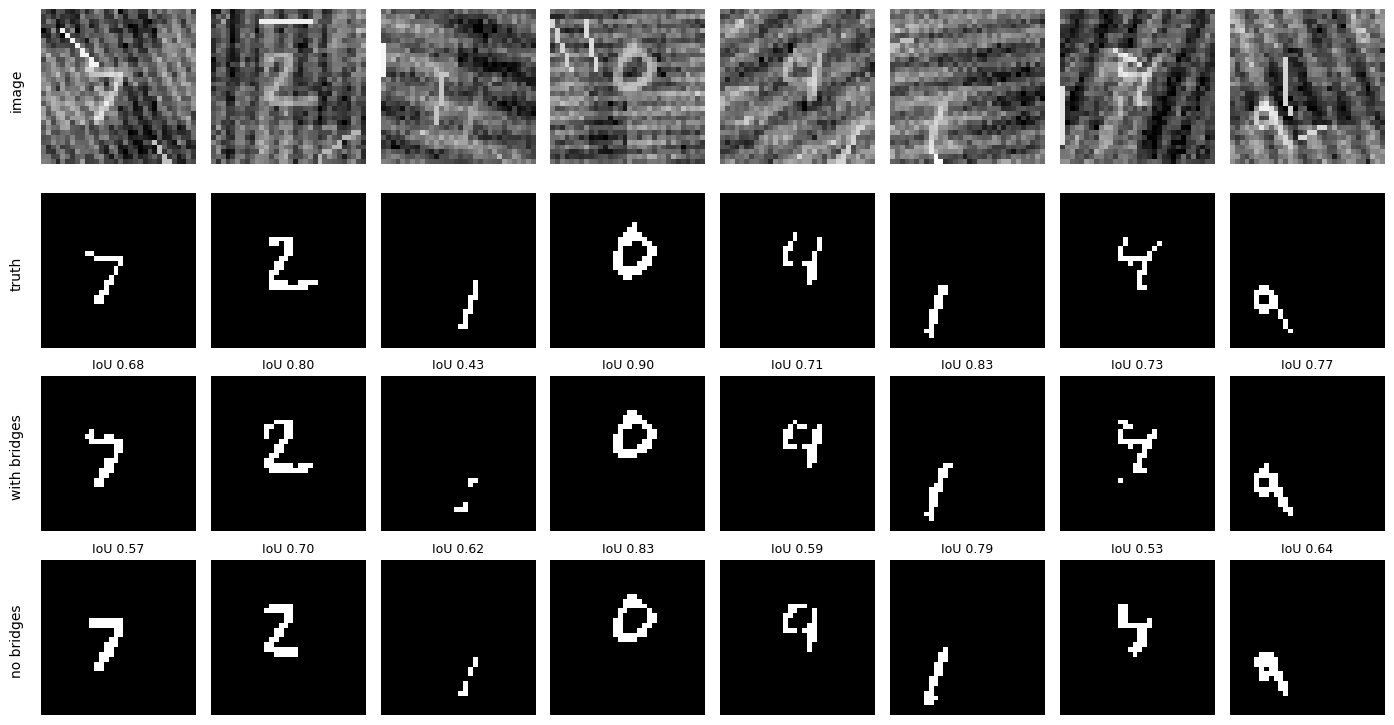

mean per-picture IoU: with bridges 0.706 | no bridges 0.563
pictures where the bridged network is better: 89.5%; worse: 8.5%


In [17]:
show_idx = list(range(8))
rows = [("image", x_test[..., 0]), ("truth", m_test), ("with bridges", pred_skip), ("no bridges", pred_noskip)]
fig, ax = plt.subplots(4, 8, figsize=(14, 7.4))
for r, (label, arr) in enumerate(rows):
    for c, k in enumerate(show_idx):
        ax[r, c].imshow(arr[k], cmap="gray", vmin=0, vmax=1)
        ax[r, c].axis("off")
        if r >= 2:
            ax[r, c].set_title(f"IoU {seg_scores(arr[k], m_test[k])['iou']:.2f}", fontsize=9)
    ax[r, 0].text(-4, 16, label, rotation=90, va="center", ha="right")
plt.tight_layout(); plt.show()

per_image = lambda pred: np.array([seg_scores(pred[k], m_test[k])["iou"] for k in range(len(m_test))])
iou_skip, iou_noskip = per_image(pred_skip), per_image(pred_noskip)
print(f"mean per-picture IoU: with bridges {iou_skip.mean():.3f} | no bridges {iou_noskip.mean():.3f}")
print(f"pictures where the bridged network is better: {(iou_skip > iou_noskip).mean():.1%}; "
      f"worse: {(iou_skip < iou_noskip).mean():.1%}")

### Why we see this

The masks without bridges are in the right place and have the wrong outline: thicker and lumpier, with
small features lost (the loop of the 9 filled in, the hook of the 7 gone). The U-Net's masks follow the
strokes. It wins on 89.5% of the test pictures and loses on 8.5%.

Look also at what both networks get wrong: a stray stroke that touches the digit, a faint digit on bright
stripes. Those are "what" mistakes, and bridges do not fix them.

---
## Step 18 - Augmenting a segmentation pair without spoiling it

Masks are the most expensive labels there are, so augmentation matters more here than anywhere. Two rules:

1. **Whatever geometric change you make to the image, make the same change to the mask.** Flip one and
   not the other and every label is in the wrong place.
2. **Never blend mask values.** Resizing an image with bilinear interpolation averages neighbouring
   pixels, which is what you want for brightness. Averaging class labels gives 0.37 of a digit, which is
   not a class.

> **Predict:** resize one mask from 32 × 32 to 48 × 48 with bilinear interpolation. How many different
> values will it contain? And with nearest-neighbour?

In [18]:
img, msk = x_test[1], m_test[1]
flip_both = (np.flip(img, axis=1), np.flip(msk, axis=1))
flip_image_only = (np.flip(img, axis=1), msk)
bright = img[..., 0] > 0.75
agree = lambda im, mk: (im[..., 0][mk == 1]).mean()
print(f"mean brightness under the mask: original {agree(img, msk):.2f} | both flipped {agree(*flip_both):.2f} | "
      f"image flipped, mask not {agree(*flip_image_only):.2f}")

m4 = msk[None, ..., None].astype("float32")
bilinear = tf.image.resize(m4, (48, 48), method="bilinear").numpy()[0, ..., 0]
nearest = tf.image.resize(m4, (48, 48), method="nearest").numpy()[0, ..., 0]
values = np.unique(np.round(bilinear, 3))
print(f"bilinear: {len(values)} different values, e.g. {values[:6]}")
print(f"          {((bilinear > 0) & (bilinear < 1)).sum()} of {bilinear.size} pixels are neither 0 nor 1")
print(f"nearest : values {np.unique(nearest)}")
print(f"cast the bilinear mask to integers and {int((bilinear > 0).sum() - bilinear.astype('uint8').sum())} "
      f"partly-digit pixels silently become background")

mean brightness under the mask: original 0.65 | both flipped 0.65 | image flipped, mask not 0.49
bilinear: 17 different values, e.g. [0.    0.028 0.083 0.139 0.167 0.25 ]
          141 of 2304 pixels are neither 0 nor 1
nearest : values [0. 1.]
cast the bilinear mask to integers and 141 partly-digit pixels silently become background


### Why we see this

Flip both and the mask still sits on the bright strokes. Flip only the image and the mask sits on whatever
happens to be there now, so the brightness under it falls to that of ordinary background. Nothing crashes;
the network is trained on wrong answers.

The bilinear mask contains many values between 0 and 1. Cast to integers, every one of them becomes 0 and
the digit gets thinner; fed to a loss as they are, they are labels that mean nothing. Nearest-neighbour
copies whole labels and keeps the mask a mask. **Interpolate the image any way you like; resize the mask
with nearest-neighbour only.** In Keras: `layers.Resizing(..., interpolation="nearest")` or
`tf.image.resize(..., method="nearest")` for the mask.

The same care applies when scoring. If the network works at a reduced size, bring its **prediction** up to
the original size and score against the original mask. Scoring against a shrunken mask rewards the model
for the detail the shrinking removed.

In [19]:
print(f"whole notebook: {time.time() - t_start:.0f} s")
print()
show("always background", always_bg)
for label, s in results.items():
    show(label, s)

whole notebook: 295 s

always background          pixel acc 0.9700 | IoU 0.0000 | Dice 0.0000 | precision 0.000 | recall 0.000
U-Net, cross-entropy       pixel acc 0.9897 | IoU 0.6924 | Dice 0.8183 | precision 0.864 | recall 0.777
U-Net, Dice                pixel acc 0.9886 | IoU 0.7018 | Dice 0.8248 | precision 0.764 | recall 0.896
U-Net, CE + Dice           pixel acc 0.9903 | IoU 0.7256 | Dice 0.8410 | precision 0.824 | recall 0.858
no bridges, CE + Dice      pixel acc 0.9848 | IoU 0.5905 | Dice 0.7425 | precision 0.754 | recall 0.731
no bridges, wider (17)     pixel acc 0.9862 | IoU 0.6323 | Dice 0.7748 | precision 0.757 | recall 0.794


---
## Trials: change one thing at a time

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Step 2: `DS = 24` (a bigger digit with fatter strokes), then rerun everything | Foreground fraction? Does the gap between bridges and no bridges grow or shrink? | |
| 2 | Step 15: `train_and_score("no bridges, CE", sce, skips=False)` | Is the no-bridge network hurt more or less under plain cross-entropy? | |
| 3 | Step 8: `build_unet(depth=3)` (bottom at 4 × 4) with and without bridges | Parameter count first. Which of the two networks minds the extra pooling? | |
| 4 | Step 14: `train_and_score("resize", ce_plus_dice, up="resize")` | Parameter count (the 2 × 2 transposed layers become 3 × 3 convolutions: 129,570)? Any change in IoU? | |
| 5 | Step 12: `EPOCHS = 15` | Which closes first: the gap between the losses, or the gap between bridges and no bridges? | |
| 6 | Step 2: remove the two stray strokes | How much of the remaining error was clutter mistaken for digit? | |
| 7 | Step 1: `SEED = 1`, then rerun everything | Which run changes most? (Watch Step 13.) | |
| 8 | Step 4: score `m_test` against a prediction of all ones | Pixel accuracy, IoU and Dice of "always digit"? (IoU is not zero.) | |

---
## Exercises

1. **Two classes of object.** Paint two digits per picture and make the mask 0 for background, 1 for
   even digits and 2 for odd digits. Set `out_channels=3`, keep sparse cross-entropy, and report the IoU
   of each class separately. Which class is harder, and is the hard part "where" or "what"?
2. **Instances.** Paint two digits of the same class. A semantic mask marks both as 1. Turn the predicted
   mask into instances by labelling connected blobs (a flood fill in NumPy is enough). When does this
   simple recipe fail?
3. **How wide must it be?** Step 15 showed that 2,011 extra weights do not replace the bridges. Widen the
   bridgeless network further (`base=24`, `base=32`), count the parameters first, and find out whether any
   width closes the gap, and at what cost in time.
4. **One bridge at a time.** Change `build_unet` to accept a list such as `skips=[True, False]` and train
   the two half-bridged networks. Which bridge matters more: the one at full resolution or the one at
   half?
5. **A boundary-weighted loss.** Give edge pixels (Step 16) a weight of 5 in the cross-entropy using
   `sample_weight` of shape `(N, 32, 32)`. Does the error on edge pixels fall, and what happens elsewhere?
6. **Threshold instead of argmax.** Take the digit probability from the cross-entropy network and call a
   pixel "digit" above a threshold of 0.3, 0.5 and 0.7. Plot precision and recall against the threshold
   and find where the IoU peaks. Was 0.5 the best choice?

---
## Cheat sheet

| Fact | Value / rule |
|---|---|
| Segmentation output | `(B, H, W, classes)`, softmax over the last axis; labels `(B, H, W)` integers |
| Classes | objects + 1: background is class 0 and has its own channel |
| Loss | per-pixel cross-entropy, usually plus Dice; Dice alone can collapse to "predict nothing" |
| Pixel accuracy | misleading when the foreground is small: "always background" scores the background fraction |
| IoU (Jaccard) | TP / (TP + FP + FN); mean IoU averages over classes, so report per class too |
| Dice | 2·TP / (2·TP + FP + FN) = 2·IoU / (1 + IoU); never below IoU |
| Transposed convolution | each input cell stamps a kernel; out = (in − 1)·stride + kernel (valid), in·stride (same) |
| Checkerboard | uneven overlap when the kernel is not a multiple of the stride; use 2 × 2 at stride 2, or resize then convolve |
| U-Net | contracting path, bottom, expanding path, and bridges that concatenate same-size maps |
| Concatenate | channels add: 32 + 32 = 64, so the next 3 × 3 convolution to 32 filters costs 18,464, not 9,248 |
| This lab, one seed | IoU: always background 0, cross-entropy 0.69, Dice 0.70, both 0.73, no bridges 0.59 (wider: 0.63) |
| TinyUNet | 32 × 32 × 1 in, 16 / 32 / 64 filters, 116,770 parameters; 105,250 without bridges |
| Input size | height and width divisible by 2 to the number of pooling steps |
| Augmentation | same geometric transform for image and mask; nearest-neighbour for the mask |
| Second life | the same network with a noisy image in and predicted noise out is the denoiser of Chapter 50 |